# Objectif 

Test de l'hypothèse de variété sur les données d'une unique section de la portion 5. 

L'objectif est de tester les performances de la méthode de localisation après projection dans un espace de dimension réduite. 

Date de création : 10/10/2026

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *
from real_data_analysis.acouplane.src.acouplane_portion_io import list_stored_intersections, open_portion
from real_data_analysis.acouplane.src.acouplane_features import (
    feature_distances_between_datasets,
)

In [3]:
# ======================================================================================================================
# Import
# ======================================================================================================================
import os
import pandas as pd

from real_data_analysis.acouplane.src.acouplane_cst import (
    ACOUPLANE_PORTION_NC_ROOT_FPATH,
    ROOT_ACOUPLANE_PROCESSED_IMG_DIR,
)
from real_data_analysis.acouplane.src.acouplane_combination import (
    RCV_COMBINATION_METHODS,
    combination_intersection_positions,
    enumerate_rcv_combinations,
    format_rcv_combination,
    rcv_combination_records,
)
from real_data_analysis.acouplane.src.acouplane_console import (
    make_figure_saver,
    make_logger,
)
from real_data_analysis.acouplane.src.acouplane_conventions import (
    library_event_error_mode,
)
from real_data_analysis.acouplane.src.acouplane_event import (
    apply_mfp_strategy_to_portions,
    build_portion_event_from_active_section,
    build_portion_library,
    get_crossing_distance_m,
    library_event_crossing_distances,
)
from real_data_analysis.acouplane.src.acouplane_localization import (
    add_validity_column,
    best_rcv_pair_per_distance,
    pivot_error_summary,
    select_and_order_distance_types,
    summarize_localization_errors,
)
from real_data_analysis.acouplane.src.acouplane_plot_analysis import (
    plot_error_cdf,
    plot_metric_vs_n_rcv,
    plot_rcv_pair_performance_heatmaps,
)
from real_data_analysis.acouplane.src.acouplane_plot_event import (
    plot_library_and_event_map,
)
from real_data_analysis.acouplane.src.acouplane_plot_mfp import (
    ambiguity_figure_filename,
    plot_combined_intersection_ambiguity,
    plot_combined_intersection_gamma_comparison,
)
from real_data_analysis.acouplane.src.acouplane_portion_io import (
    list_stored_intersections,
    open_portion,
    section_name_of,
)

# Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. Les fichiers sont ouverts de façon paresseuse (rien n'est chargé en mémoire avant l'accès aux valeurs).

In [4]:
portion_id = 5
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = open_portion(fpath)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB ...
│   │       Attributes:
│   │           description:              Posi

# Rappel de la position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

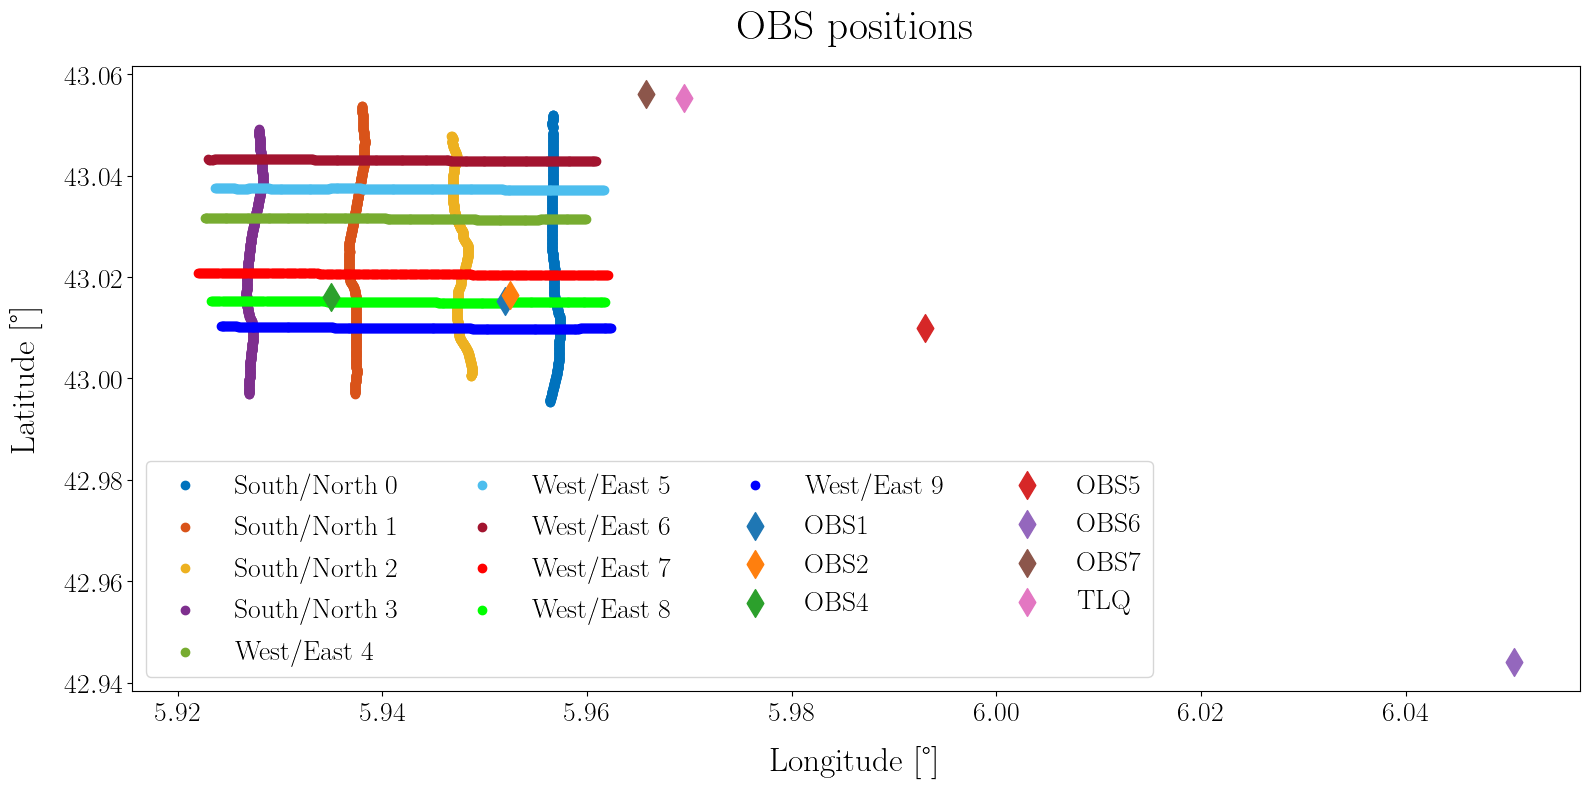

In [5]:
plot_portion_tir_pos(portion_tree=portion)

# Analyse de la structure de variété des données 

## Choix de l'intersection 
On s'intéresse ici à une unique intersection 

In [6]:
obs_ids = ["obs1", "obs2", "obs4", "obs7"]

test_section = "oe7"
reference_rcv = 'obs1'
fmin = 10
fmax = 500

event_rtf_method = "spectral_ratio"

In [7]:
portion = portion.sel(freq=slice(fmin, fmax))
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB 43.05 43.05 ... 43.0 43.0
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB 43.0 43.0 ... 43.05 43.05
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB ...
│   │       Attributes:
│ 

In [8]:
# The test section plays the role of the event
portion_event = build_portion_event_from_active_section(
    portion,
    test_section,
    rcv_ref=reference_rcv,
    fmin=fmin,
    fmax=fmax,
    rtf_method=event_rtf_method,
)
portion_event

<xarray.DataTree>
Group: /
│   Attributes:
│       description:  Event built from the section 'oe7'
├── Group: /position
│   └── Group: /position/oe7
│           Dimensions:   (datetime: 376)
│           Coordinates:
│             * datetime  (datetime) datetime64[ns] 3kB 2026-02-25T06:04:00.600098 ... 20...
│           Data variables:
│               lon       (datetime) float64 3kB 5.962 5.962 5.962 ... 5.923 5.922 5.922
│               lat       (datetime) float64 3kB 43.02 43.02 43.02 ... 43.02 43.02 43.02
│           Attributes: (12/13)
│               description:            Localisation features
│               campagne:               ACOUPLANE
│               geodesic_frame:         WGS84
│               portion_id:             5
│               section_orientation:    West/East
│               section_id:             7
│               ...                     ...
│               obs_position:           OBS position corrected using LMS inversion.
│               obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
│               reference_receiver:     obs1
│               rtf_method:             spectral_ratio
│               acquisition_mode:       active
│               event_id:               oe7
└── Group: /feature
    └── Group: /feature/oe7
            Dimensions:         (rcv_id_feature: 5, event_datetime: 376, freq: 2008,
                                 rcv_id: 7)
            Coordinates:
              * rcv_id_feature  (rcv_id_feature) <U4 80B 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
              * event_datetime  (event_datetime) datetime64[ns] 3kB 2026-02-25T06:04:00.6...
              * freq            (freq) float64 16kB 10.01 10.25 10.5 ... 499.5 499.8 500.0
              * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
            Data variables:
                pi_ij           (rcv_id_feature, event_datetime, freq) complex64 30MB (3....
                gamma_ij        (rcv_id_feature, event_datetime, freq) float32 15MB 11.71...
                sij_scot        (rcv_id_feature, event_datetime, freq) complex64 30MB (0....
                event_lon       (event_datetime) float64 3kB 5.962 5.962 ... 5.922 5.922
                event_lat       (event_datetime) float64 3kB 43.02 43.02 ... 43.02 43.02
                rcv_lon         (rcv_id) float64 56B ...
                rcv_lat         (rcv_id) float64 56B ...
                rcv_immersion   (rcv_id) int16 14B ...
            Attributes:
                description:            Localisation features
                campagne:               ACOUPLANE
                geodesic_frame:         WGS84
                portion_id:             5
                section_orientation:    West/East
                section_id:             7
                section_label:          oe7
                obs_position:           OBS position corrected using LMS inversion.
                obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
                reference_receiver:     obs1
                rtf_method:             spectral_ratio
                acquisition_mode:       active

### Définition de la méthode d'apprentissage de variété

On utilise ici la méthode ISOMAP qui à pour propriété (pour objectif) de préserver les distances géodésiques entre éléments du jeu de données. 

**Remarque** : on utilise ici le mode *metric = precomputed* qui permet de fournir directement une matrice de distance $M$ décrivant la distance entre chaque pair d'éléments du jeu de données.  

### Calcul de la matrice des distances 

In [15]:
receiver = 'obs2'
portion_ = portion.sel(rcv_id_feature=[receiver])
portion_event = portion_event.sel(rcv_id_feature=[receiver])

In [16]:
ds_feature = portion_event.feature[test_section].to_dataset()
feature_distances = feature_distances_between_datasets(
    ds_feature_a=ds_feature,
    ds_feature_b=ds_feature,
    compare_centered_gamma=True,
)

In [17]:
# Pick among available :[
#  'dist_theta',
#  'dist_theta_gamma',
#  'dist_L2_gamma',
#  'dist_dcf',
#  'dist_theta_gamma_centered',
#  'dist_L2_gamma_centered'
# ]
dist_metric = "dist_theta_gamma_centered"

dist_matrix = feature_distances[dist_metric]
# Remove rcv dimension = 1
dist_matrix = np.squeeze(dist_matrix)   
dist_matrix.shape

(376, 376)

In [18]:
from sklearn import manifold
from sklearn.preprocessing import StandardScaler

In [28]:
n_neighbors_ = np.arange(5, 100, 5).astype(int)
n_components = 100
reconstruction_error = []
coords_var = []
for n_neighbors in n_neighbors_:
    # Define isomap object
    iso = manifold.Isomap(
        n_neighbors=n_neighbors,
        n_components=n_components,
        metric="precomputed",
    )
    # Learn manifold and project data in target dimension
    coords = iso.fit_transform(dist_matrix)
    cvar = np.var(coords, axis=0)
    cvar = cvar / cvar.max()

    coords_var.append(cvar)
    reconstruction_error.append(iso.reconstruction_error())

coords_var = np.asarray(coords_var)
reconstruction_error = np.asarray(reconstruction_error)

Text(0, 0.5, 'Variance')

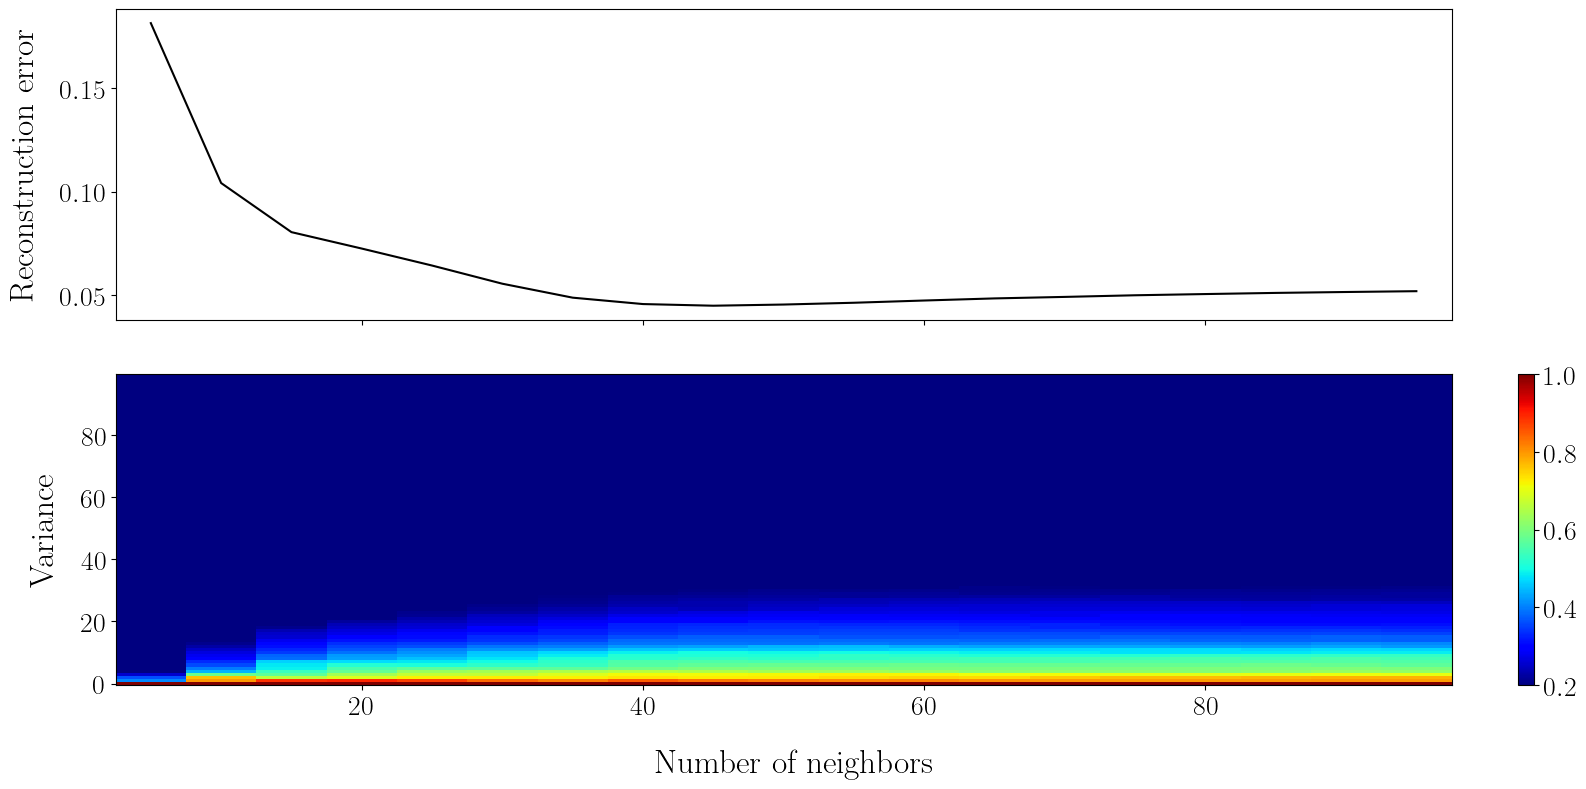

In [29]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
axs[0].plot(n_neighbors_, reconstruction_error, color="k")
im = axs[1].pcolormesh(n_neighbors_, np.arange(n_components), coords_var.T, cmap="jet", vmin=0.2)
plt.colorbar(im, ax=axs[1])

fig.supxlabel("Number of neighbors")
axs[0].set_ylabel("Reconstruction error")
axs[1].set_ylabel("Variance")

**Choix des paramètres ISOMAP** Le choix du nombre de voisins est un compromis ici entre l'erreur de reconstruction et la vitesse de décroissance de la variance des coordonnées. Le nombre de voisins à cependant une faible influence sur la variance des coordonnées. 

Le choix n = 20 semble être un bon compromis avec une relativement faible erreur de reconstruction et un gradient relativement important de la variance. 


In [33]:
# ISOMAP
n_components = 100
n_neighbors = 10

# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors,
    n_components=n_components,
    metric="precomputed",
)

In [34]:
# Learn manifold and project data in target dimension
coords = isomap_obj.fit_transform(dist_matrix)

# Normalize coords
norm_factor = np.max(coords)
coords /= norm_factor

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_16460\606414193.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


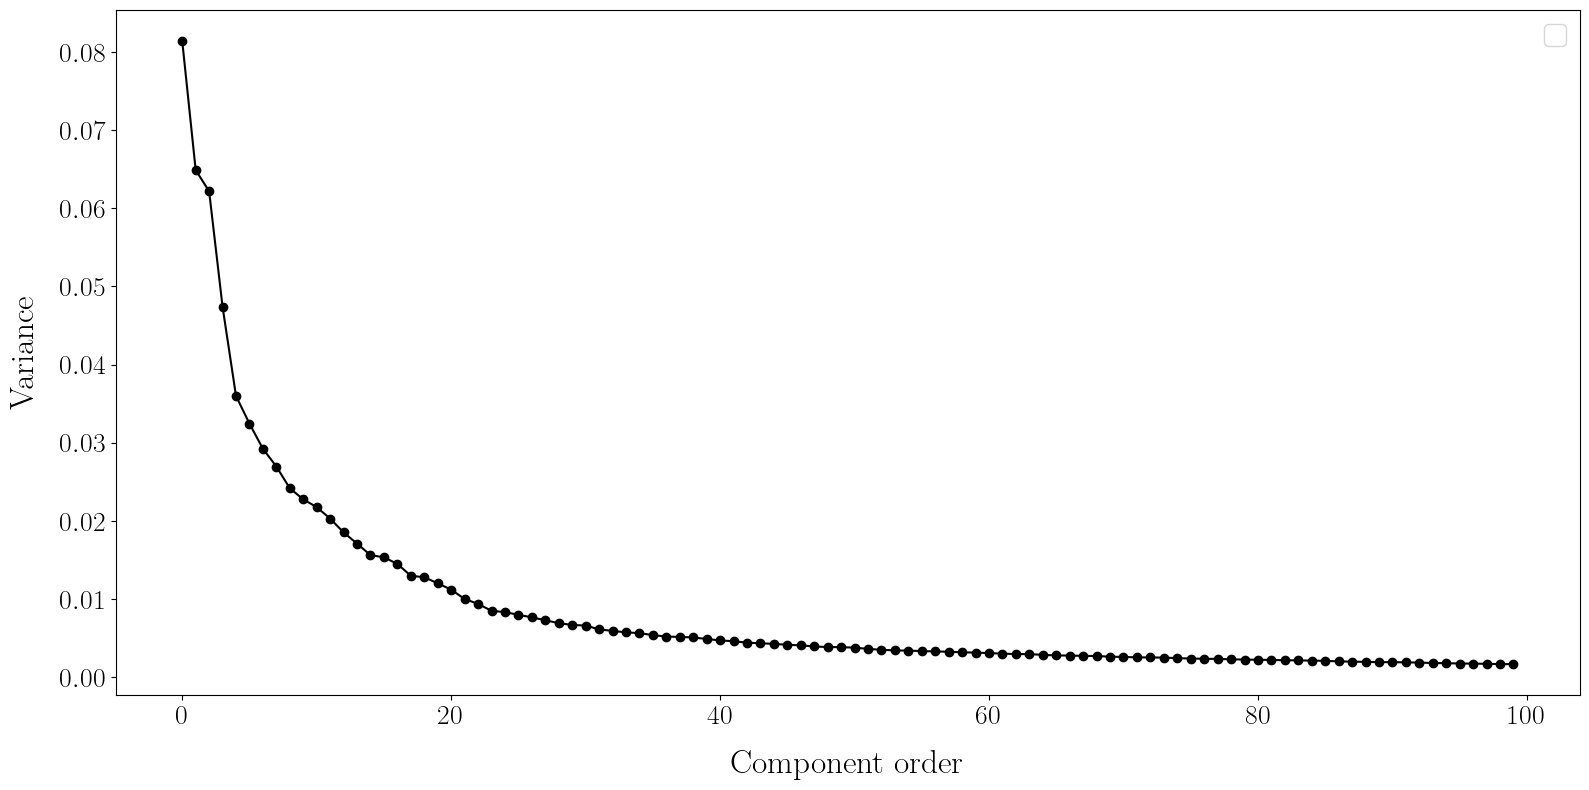

In [35]:
# Plot variance of each component
cvar = np.var(coords, axis=0)
plt.figure()
plt.plot(np.arange(cvar.size), cvar, marker="o", color="k")
plt.xlabel("Component order")
plt.ylabel("Variance")
plt.legend()
# plt.ylim(0, 0.05)

On peut vérifier que l'erreur de reconstruction décroit rapidement. 

In [36]:
proj_dims = np.arange(10, n_components, 10).astype(int)

reconstruction_error = []
for p_dim in proj_dims:
    # Define isomap object
    iso = manifold.Isomap(
        n_neighbors=n_neighbors,
        n_components=p_dim,
        metric="precomputed",
    )
    # Learn manifold and project data in target dimension
    iso.fit(dist_matrix)

    reconstruction_error.append(iso.reconstruction_error())

reconstruction_error = np.asarray(reconstruction_error)

Text(0, 0.5, 'Reconstruction error')

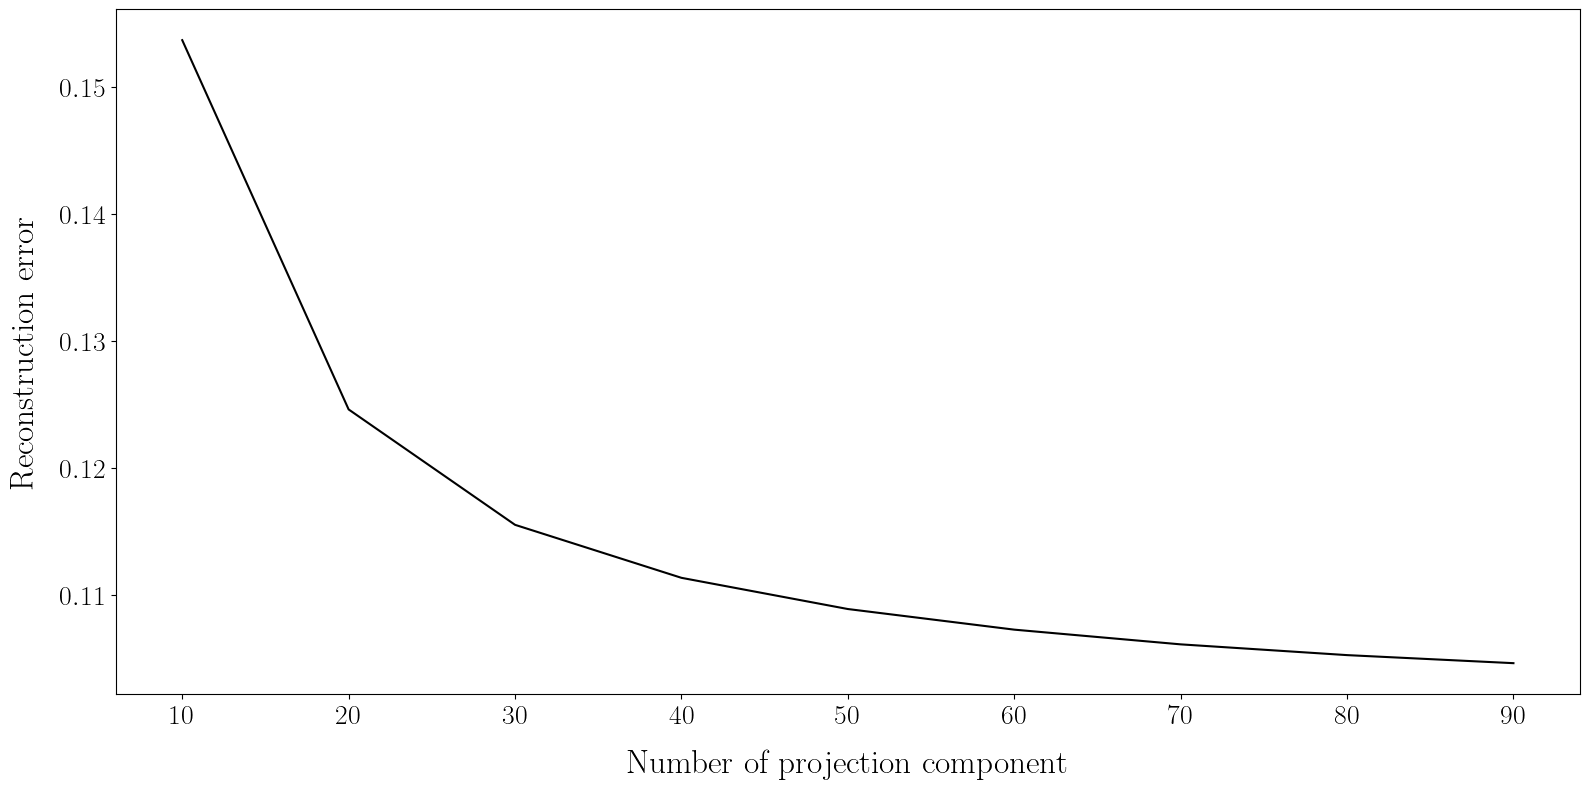

In [37]:
plt.figure()
plt.plot(proj_dims, reconstruction_error, color="k")
plt.xlabel("Number of projection component")
plt.ylabel("Reconstruction error")

On réduit ensuite la dimension à d = 20. 

In [38]:
low_dim = 20
coords_low_dim = coords[:, :low_dim]
coords_low_dim.shape

dist_low_dim = np.sqrt(
    np.nansum(
        (coords_low_dim[:, np.newaxis, :] - coords_low_dim[np.newaxis, :, :]) ** 2,
        axis=-1,
    )
)

Text(0.02, 0.5, 'Replica index')

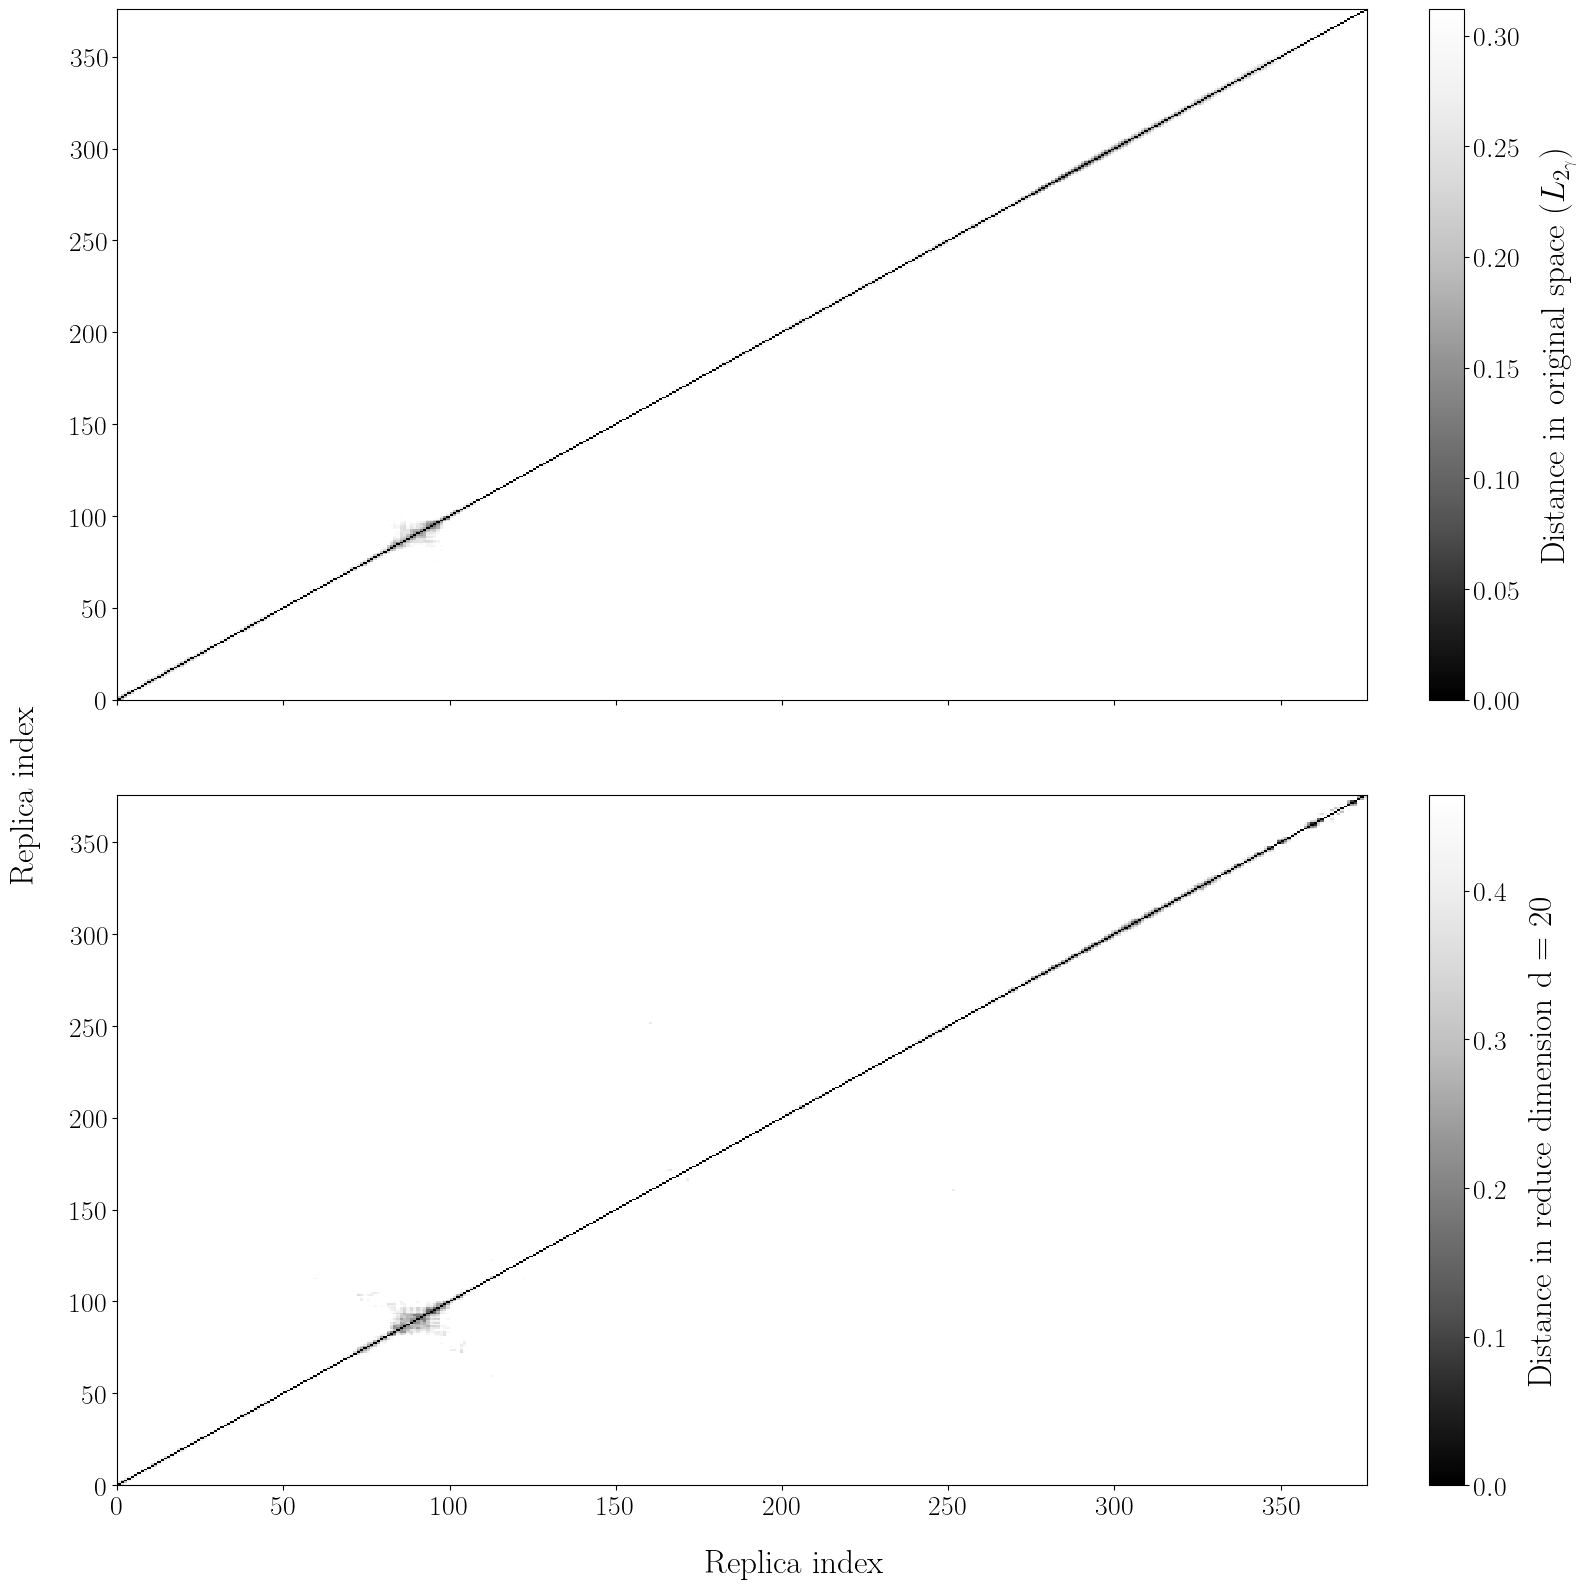

In [40]:
cmap = "Grays_r"
# cmap = "jet_r"
fig, axs = plt.subplots(2, 1, figsize=(16, 16), sharey=True, sharex=True)

# vmin = min(np.percentile(data, 0.05) for data in [dist_matrix, dist_low_dim])
# vmax = max(np.percentile(data, 0.95) for data in [dist_matrix, dist_low_dim])

# im = axs[0].pcolormesh(
#     dist_matrix, cmap="Grays_r", vmin=vmin, vmax=vmax
# )
# im = axs[1].pcolormesh(dist_low_dim, cmap="Grays_r", vmin=vmin, vmax=vmax)


# fig.colorbar(
#     im,
#     ax=axs[:].tolist(),
#     location="right",
#     label=r"$L_{2_\gamma}$",
#     pad=0.02,
#     fraction=0.04,
# )

# vmin = min(np.percentile(data, 0.05) for data in [dist_matrix, dist_low_dim])
# vmax = max(np.percentile(data, 0.95) for data in [dist_matrix, dist_low_dim])

im = axs[0].pcolormesh(
    dist_matrix,
    cmap=cmap,
    vmin=np.percentile(dist_matrix, 0.05),
    vmax=np.percentile(dist_matrix, 0.95),
)
plt.colorbar(im, label=r"Distance in original space ($L_{2_\gamma}$)", ax=axs[0])

im = axs[1].pcolormesh(
    dist_low_dim,
    cmap=cmap,
    vmin=np.percentile(dist_low_dim, 0.05),
    vmax=np.percentile(dist_low_dim, 0.95),
)
plt.colorbar(im, label=f"Distance in reduce dimension d = {low_dim}", ax=axs[1])

# fig.colorbar(
#     im,
#     ax=axs[:].tolist(),
#     location="right",
#     label=r"$L_{2_\gamma}$",
#     pad=0.02,
#     fraction=0.04,
# )

# plt.colorbar(im, label=f"Distance in reduce dimension d = {low_dim}")

fig.supxlabel("Replica index")
fig.supylabel("Replica index")

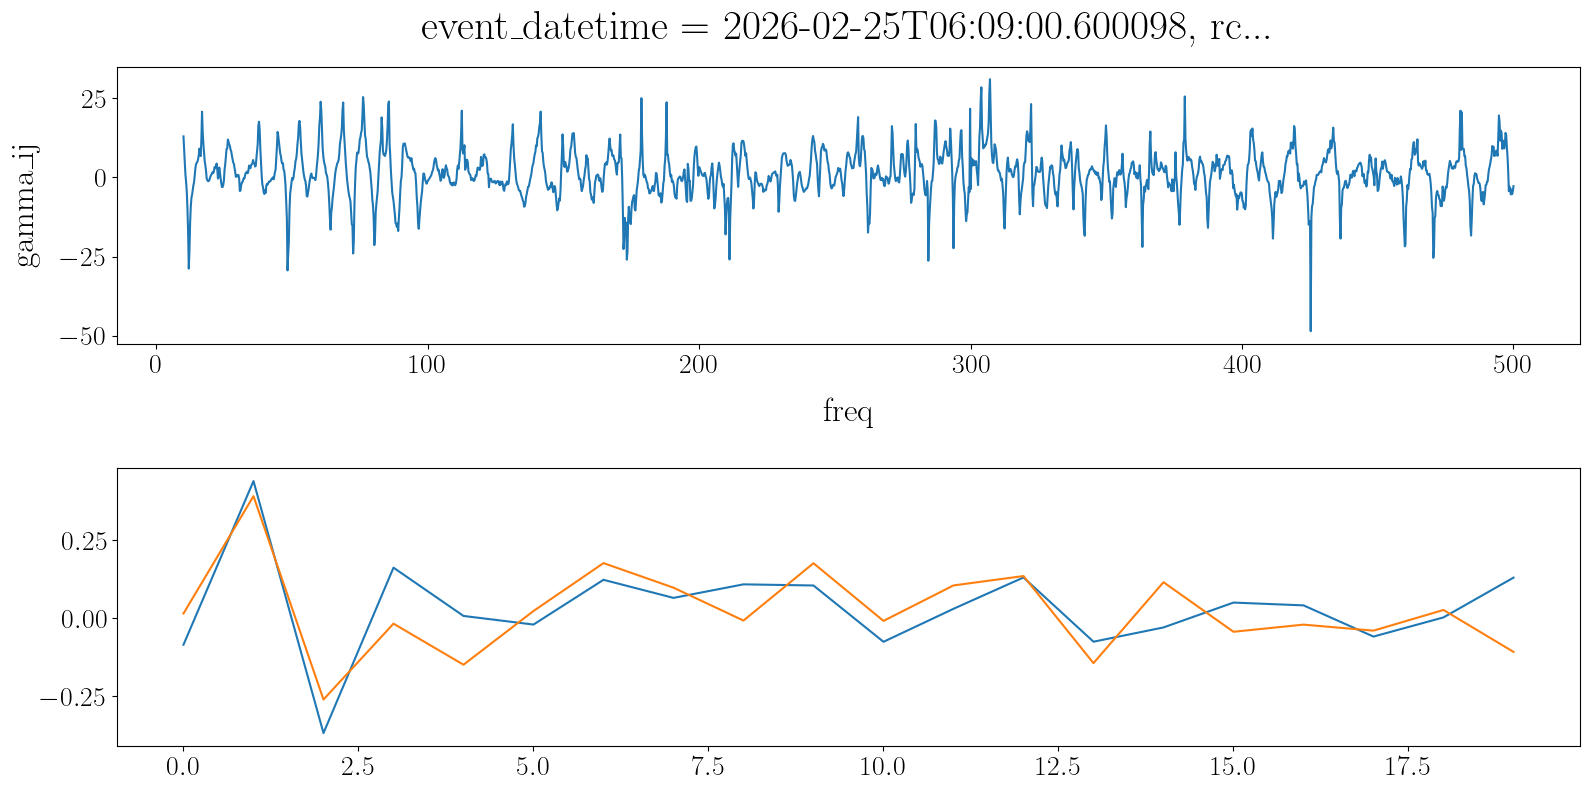

In [45]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ds_feature.gamma_ij.isel(event_datetime=100).plot(x="freq", ax=axs[0])
axs[1].plot(np.arange(coords_low_dim[100, :].size), coords_low_dim[100, :])
axs[1].plot(np.arange(coords_low_dim[100, :].size), coords_low_dim[102, :])

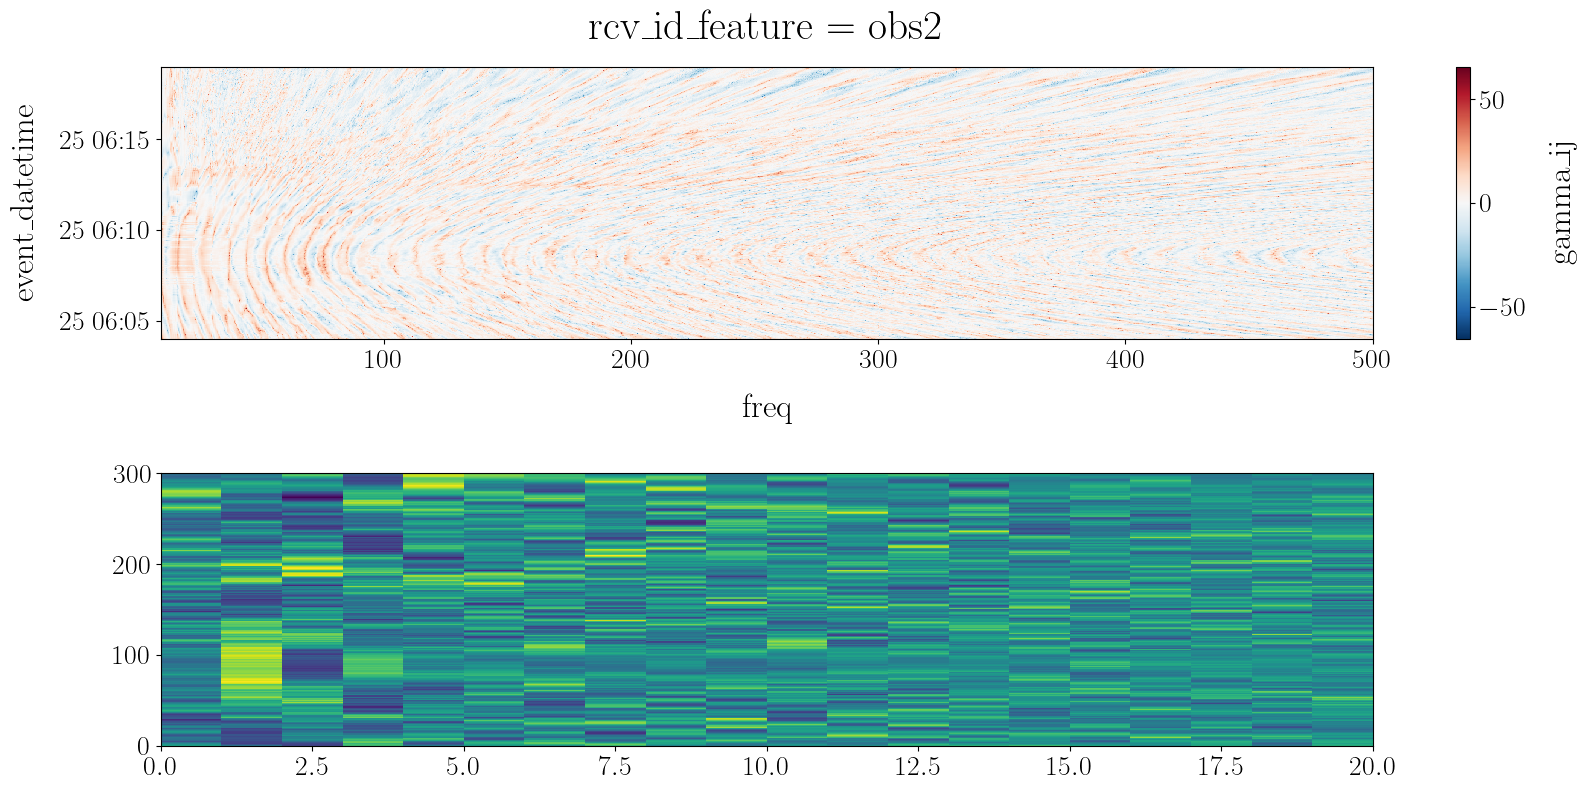

In [43]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))
sl = slice(0, 300)

ds_feature.gamma_ij.isel(event_datetime=sl).plot(
    x="freq", y="event_datetime", ax=axs[0]
)
axs[1].pcolormesh(coords_low_dim[sl, :])
# axs[1].plot(np.arange(coords_low_dim[100, :].size), coords_low_dim[102, :])

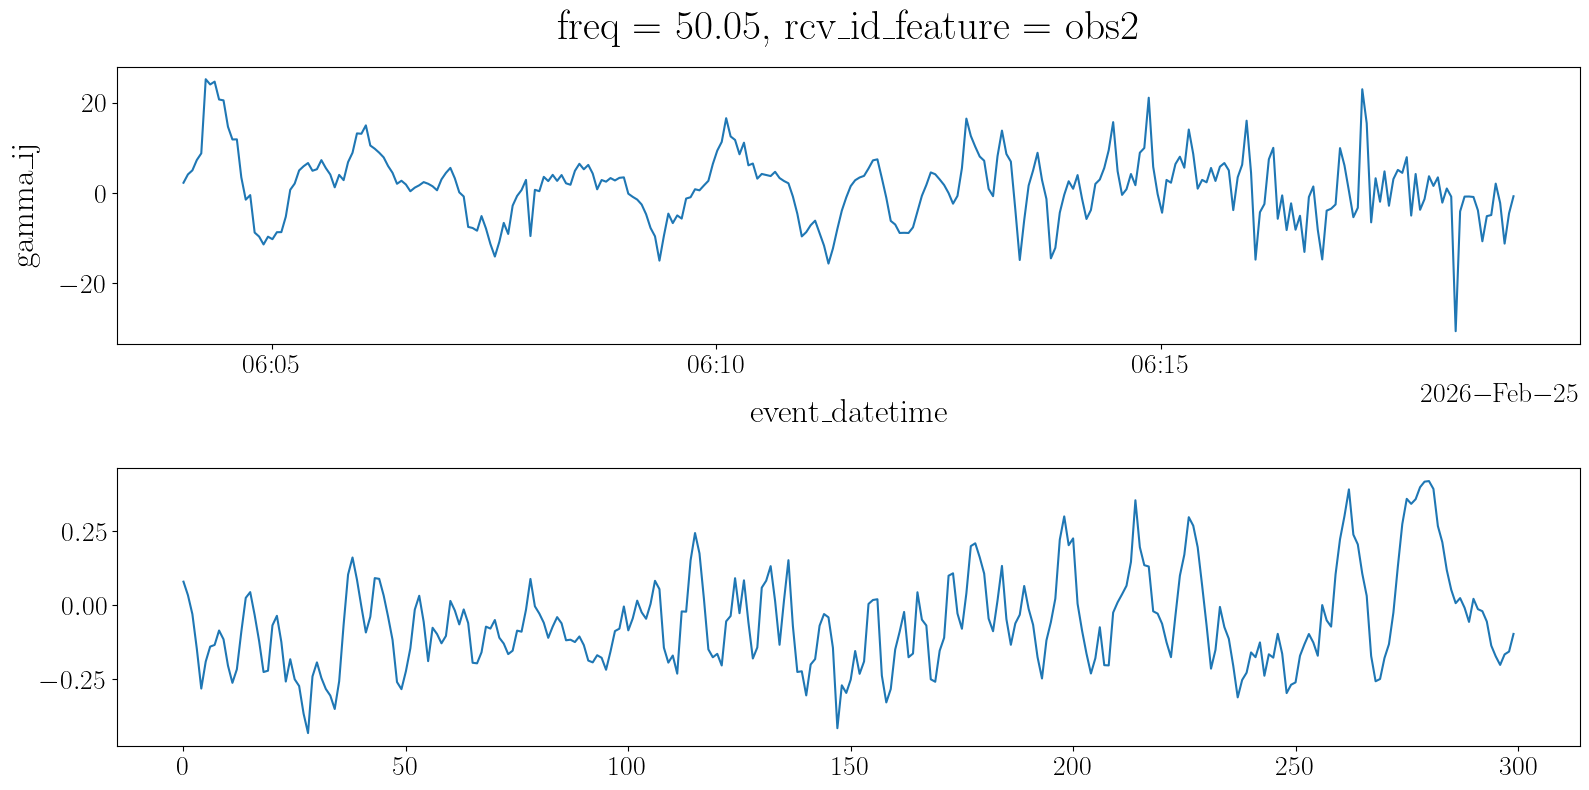

In [44]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

sl = slice(0, 300)
ds_feature.gamma_ij.isel(event_datetime=sl).sel(freq=50, method="nearest").plot(
    ax=axs[0]
)
axs[1].plot(np.arange(coords_low_dim[sl, :].shape[0]), coords_low_dim[sl, 0])
# axs[1].pcolormesh(coords_low_dim[:150, :])